# ARTI 502 Final Project: Experimental Setup, Performance Measures and Optimization
**(Sections 5.2, 5.3, 5.4)** · Custom CNN vs. YOLOv8n-cls on GTSRB (43 classes)


### 1. Install packages (run once)

In [1]:
# Run this cell once, then restart the kernel (VS Code: "Restart" button at the top of the notebook).
%pip install torch torchvision ultralytics scikit-learn kagglehub pandas matplotlib pillow

   ---------------------------------------- 0.0/1.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.5 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.5 MB ? eta -:--:--
   --------------------- ------------------ 0.8/1.5 MB 2.5 MB/s eta 0:00:01
   ---------------------------------------- 1.5/1.5 MB 3.1 MB/s  0:00:00
   ---------------------------------------- 0.0/911.5 kB ? eta -:--:--
   ---------------------------------------- 911.5/911.5 kB 13.1 MB/s  0:00:00
   ---------------------------------------- 0.0/53.9 MB ? eta -:--:--
   -- ------------------------------------- 3.1/53.9 MB 14.6 MB/s eta 0:00:04
   ----- ---------------------------------- 7.6/53.9 MB 18.1 MB/s eta 0:00:03
   --------- ------------------------------ 12.6/53.9 MB 20.3 MB/s eta 0:00:03
   -------------- ------------------------- 19.4/53.9 MB 23.6 MB/s eta 0:00:02
   ------------------- -------------------- 26.5/53.9 MB 25.6 MB/s eta 0:00:02
   ------------------------- ---

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


### 2. Imports and experiment configuration

In [12]:
import os, time, json, random, platform, itertools, copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import v2

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             f1_score, confusion_matrix, classification_report)

# ---------------- configuration ----------------
QUICK_RUN = False          # True = tiny smoke test (subset + 1 epoch). Use False for the report.
SEED = 42
NUM_CLASSES = 43
VAL_FRACTION_FOLDS = 5     # 1 of 5 stratified group folds -> ~20% validation

CNN_IMG = 48               # custom CNN input size (48x48 RGB)
YOLO_IMG = 64              # YOLOv8n-cls input size (must be a multiple of 32)

TUNE_EPOCHS_CNN = 4        # epochs per configuration during the search
TUNE_EPOCHS_YOLO = 3
FINAL_EPOCHS = 20      # maximum epochs for the final models
PATIENCE = 5               # early stopping patience (epochs without val macro-F1 improvement)

CNN_GRID = {"lr": [1e-3, 5e-4], "batch_size": [64], "dropout": [0.3, 0.5]}
YOLO_GRID = {"optimizer": ["SGD", "AdamW"], "lr0": [1e-2, 1e-3]}
YOLO_BATCH = 64

LATENCY_IMAGES = 300       # test images used to time single-image inference (batch size 1, CPU)

if QUICK_RUN:
    TUNE_EPOCHS_CNN = TUNE_EPOCHS_YOLO = FINAL_EPOCHS = 1
    CNN_GRID = {"lr": [1e-3], "batch_size": [64], "dropout": [0.3, 0.5]}
    YOLO_GRID = {"optimizer": ["SGD", "AdamW"], "lr0": [1e-2]}
    LATENCY_IMAGES = 30

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
OUT = Path("results"); OUT.mkdir(parents=True, exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()
print("Device:", DEVICE, "| QUICK_RUN:", QUICK_RUN)

Device: cpu | QUICK_RUN: False


### 3. Record the hardware and software environment (for Table in 5.2)

In [3]:
import sklearn, ultralytics, torchvision

def cpu_name():
    name = platform.processor()
    if platform.system() == "Windows":
        try:
            import subprocess
            out = subprocess.run(["powershell", "-NoProfile", "-Command",
                                  "(Get-CimInstance Win32_Processor).Name"],
                                 capture_output=True, text=True, timeout=20).stdout.strip()
            name = out or name
        except Exception:
            pass
    return name or "unknown"

def ram_gb():
    try:
        import psutil
        return round(psutil.virtual_memory().total / 1024**3, 1)
    except Exception:
        return "unknown"

env = {
    "Operating system": f"{platform.system()} {platform.release()}",
    "CPU": cpu_name(),
    "Logical CPU cores": os.cpu_count(),
    "RAM (GB)": ram_gb(),
    "GPU": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None (CPU only)",
    "Python": platform.python_version(),
    "PyTorch": torch.__version__,
    "Torchvision": torchvision.__version__,
    "Ultralytics": ultralytics.__version__,
    "scikit-learn": sklearn.__version__,
    "NumPy": np.__version__,
    "Pandas": pd.__version__,
    "IDE": "Visual Studio Code (Jupyter Notebook)",
    "Random seed": SEED,
}
env_df = pd.DataFrame(env.items(), columns=["Item", "Value"])
env_df.to_csv(OUT / "environment.csv", index=False)
display(env_df)

Creating new Ultralytics Settings v0.0.8 file  
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\Zaina\AppData\Roaming\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


,Item,Value
0,Operating system,Windows 11
1,CPU,AMD Ryzen 7 5825U with Radeon Graphics
2,Logical CPU cores,16
3,RAM (GB),15.4
4,GPU,None (CPU only)
5,Python,3.13.9
6,PyTorch,2.14.1+cpu
7,Torchvision,0.29.1+cpu
8,Ultralytics,8.4.216
9,scikit-learn,1.7.2


### 4. Locate the GTSRB dataset and load the CSV files

In [4]:
if os.environ.get("GTSRB_DIR"):                     # optional manual path
    dataset_path = Path(os.environ["GTSRB_DIR"])
else:
    import kagglehub                                 # uses the cached download from the team notebook
    dataset_path = Path(kagglehub.dataset_download("meowmeowmeowmeowmeow/gtsrb-german-traffic-sign"))

train_df = pd.read_csv(dataset_path / "Train.csv")
test_df = pd.read_csv(dataset_path / "Test.csv")
print("Dataset:", dataset_path)
print("Train.csv:", len(train_df), "| Test.csv:", len(test_df))

100%|██████████| 612M/612M [00:29<00:00, 21.9MB/s] 

Extracting files...


Dataset: C:\Users\Zaina\.cache\kagglehub\datasets\meowmeowmeowmeowmeow\gtsrb-german-traffic-sign\versions\1
Train.csv: 39209 | Test.csv: 12630


### 5. Train / validation split (stratified **and** grouped by physical sign track)
GTSRB training images come in *tracks*: about 30 consecutive frames of the same physical sign (file name `CCCCC_TTTTT_FFFFF.png` = class_track_frame).
A plain random split would put near-identical frames in both training and validation and inflate validation scores, so whole tracks are assigned to one side only.
The official `Test.csv` is never touched until the final evaluation.

In [5]:
train_df["track"] = train_df["Path"].str.split("/").str[-1].str.split("_").str[1]
train_df["group"] = train_df["ClassId"].astype(str) + "_" + train_df["track"]

sgkf = StratifiedGroupKFold(n_splits=VAL_FRACTION_FOLDS, shuffle=True, random_state=SEED)
tr_idx, va_idx = next(sgkf.split(train_df, train_df["ClassId"], groups=train_df["group"]))
train_df["split"] = "train"
train_df.loc[train_df.index[va_idx], "split"] = "val"
test_df["split"] = "test"

assert set(train_df.loc[train_df.split == "train", "group"]).isdisjoint(
       set(train_df.loc[train_df.split == "val", "group"])), "track leakage!"

all_df = pd.concat([train_df, test_df], ignore_index=True)
if QUICK_RUN:   # small stratified subset for the smoke test only
    all_df = (all_df.sample(frac=1, random_state=SEED)
                    .groupby(["split", "ClassId"]).head(6).reset_index(drop=True))

split_table = (all_df.groupby("split").size()
               .reindex(["train", "val", "test"]).rename("Images").to_frame())
split_table["Proportion (%)"] = (100 * split_table["Images"] / split_table["Images"].sum()).round(1)
split_table["Classes"] = all_df.groupby("split")["ClassId"].nunique().reindex(split_table.index)
split_table.to_csv(OUT / "split_sizes.csv")
display(split_table)
print("Validation classes covered:", all_df.query("split=='val'").ClassId.nunique(), "/ 43")

,Images,Proportion (%),Classes
split,,,
train,31349,60.5,43
val,7860,15.2,42
test,12630,24.4,43


Validation classes covered: 42 / 43


### 6. Pre-processing: crop each sign to its ROI and save one shared folder tree
Both models read **the same** cropped images (`results/gtsrb_cls/{train,val,test}/{00..42}/`), so they see identical data.
Folders are zero-padded (`00`–`42`) so alphabetical order equals the class ID for both PyTorch and Ultralytics.

In [6]:
DATA_ROOT = Path("results/gtsrb_cls_quick" if QUICK_RUN else "results/gtsrb_cls")

def export_crops(df, root):
    written = 0
    cols = ["Path", "Roi.X1", "Roi.Y1", "Roi.X2", "Roi.Y2", "ClassId", "split"]
    for path, x1, y1, x2, y2, cls, split in df[cols].itertuples(index=False, name=None):
        dst = root / split / f"{cls:02d}" / Path(path).name
        if dst.exists():
            continue
        dst.parent.mkdir(parents=True, exist_ok=True)
        with Image.open(dataset_path / path) as im:
            # ROI corners are inclusive pixel coordinates, so +1 on the right/bottom edge
            im.convert("RGB").crop((x1, y1, x2 + 1, y2 + 1)).save(dst)
        written += 1
    return written

t0 = time.time()
n = export_crops(all_df, DATA_ROOT)
print(f"Wrote {n} new crops in {time.time()-t0:.0f}s ->", DATA_ROOT.resolve())
for s in ["train", "val", "test"]:
    print(s, sum(1 for _ in (DATA_ROOT / s).rglob("*.png")))

Wrote 51839 new crops in 849s -> C:\Users\Zaina\Downloads\results\gtsrb_cls
train 31349
val 7860
test 12630


### 7. Custom CNN data pipeline (resize to 48×48, normalise, light augmentation; **no horizontal flips**)

In [7]:
def load_split(split, size):
    xs, ys, paths = [], [], []
    for cls_dir in sorted((DATA_ROOT / split).iterdir()):
        for p in sorted(cls_dir.glob("*.png")):
            with Image.open(p) as im:
                xs.append(np.asarray(im.convert("RGB").resize((size, size), Image.BILINEAR)))
            ys.append(int(cls_dir.name)); paths.append(p)
    x = torch.from_numpy(np.stack(xs)).permute(0, 3, 1, 2).contiguous()   # uint8 N,3,H,W
    return x, torch.tensor(ys), paths

t0 = time.time()
Xtr, ytr, _ = load_split("train", CNN_IMG)
Xva, yva, _ = load_split("val", CNN_IMG)
Xte, yte, test_paths = load_split("test", CNN_IMG)
print(f"Loaded in {time.time()-t0:.0f}s:", Xtr.shape, Xva.shape, Xte.shape)

MEAN = (Xtr.float() / 255).mean(dim=(0, 2, 3))
STD = (Xtr.float() / 255).std(dim=(0, 2, 3))
print("Train channel mean:", MEAN.numpy().round(4), "std:", STD.numpy().round(4))

train_tf = v2.Compose([
    v2.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    v2.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),
])

class SignDataset(Dataset):
    def __init__(self, x, y, augment=False):
        self.x, self.y, self.augment = x, y, augment
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        img = self.x[i]
        if self.augment:
            img = train_tf(img)
        img = (img.float() / 255 - MEAN[:, None, None]) / STD[:, None, None]
        return img, self.y[i]

def make_loader(x, y, batch_size, train):
    g = torch.Generator().manual_seed(SEED)
    return DataLoader(SignDataset(x, y, augment=train), batch_size=batch_size,
                      shuffle=train, generator=g, num_workers=0)   # 0 = safe on Windows/Jupyter

Loaded in 549s: torch.Size([31349, 3, 48, 48]) torch.Size([7860, 3, 48, 48]) torch.Size([12630, 3, 48, 48])
Train channel mean: [     0.3538      0.3142      0.3306] std: [     0.2704      0.2542      0.2629]


### 8. Custom CNN architecture (Technique #1)

In [8]:
def conv_block(c_in, c_out, p_drop):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
        nn.Conv2d(c_out, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
        nn.MaxPool2d(2), nn.Dropout(p_drop / 2),
    )

class TrafficSignCNN(nn.Module):
    # 48x48x3 -> [32] 24x24 -> [64] 12x12 -> [128] 6x6 -> GAP -> FC256 -> 43 logits
    def __init__(self, num_classes=NUM_CLASSES, dropout=0.5):
        super().__init__()
        self.features = nn.Sequential(conv_block(3, 32, dropout), conv_block(32, 64, dropout),
                                      conv_block(64, 128, dropout))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                  nn.Linear(128, 256), nn.ReLU(inplace=True),
                                  nn.Dropout(dropout), nn.Linear(256, num_classes))
    def forward(self, x):
        return self.head(self.features(x))   # raw logits; CrossEntropyLoss applies log-softmax

count_params = lambda m: sum(p.numel() for p in m.parameters())
print(TrafficSignCNN())
print("Trainable parameters:", f"{count_params(TrafficSignCNN()):,}")

TrafficSignCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (7): Dropout(p=0.25, inplace=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, tra

### 9. Training and evaluation functions (Adam, cross-entropy, LR-on-plateau, early stopping on val macro-F1)

In [9]:
@torch.inference_mode()
def predict_cnn(model, loader):
    model.eval(); preds, labels, loss_sum = [], [], 0.0
    crit = nn.CrossEntropyLoss(reduction="sum")
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        out = model(xb); loss_sum += crit(out, yb).item()
        preds.append(out.argmax(1).cpu()); labels.append(yb.cpu())
    y_pred, y_true = torch.cat(preds).numpy(), torch.cat(labels).numpy()
    return y_true, y_pred, loss_sum / len(y_true)

def fit_cnn(cfg, max_epochs, patience=PATIENCE, verbose=True):
    set_seed()
    model = TrafficSignCNN(dropout=cfg["dropout"]).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=2)
    crit = nn.CrossEntropyLoss()
    tr_loader = make_loader(Xtr, ytr, cfg["batch_size"], train=True)
    va_loader = make_loader(Xva, yva, 256, train=False)
    best_f1, best_state, wait, hist = -1, None, 0, []
    t0 = time.time()
    for ep in range(1, max_epochs + 1):
        model.train(); run_loss, n = 0.0, 0
        for xb, yb in tr_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad(); loss = crit(model(xb), yb); loss.backward(); opt.step()
            run_loss += loss.item() * len(yb); n += len(yb)
        y_true, y_pred, va_loss = predict_cnn(model, va_loader)
        va_acc = accuracy_score(y_true, y_pred)
        va_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
        sched.step(va_f1)
        hist.append({"epoch": ep, "train_loss": run_loss / n, "val_loss": va_loss,
                     "val_acc": va_acc, "val_macro_f1": va_f1, "lr": opt.param_groups[0]["lr"]})
        if verbose:
            print(f"  ep {ep:2d} | train loss {run_loss/n:.4f} | val loss {va_loss:.4f} "
                  f"| val acc {va_acc:.4f} | val macro-F1 {va_f1:.4f}")
        if va_f1 > best_f1:
            best_f1, best_state, wait = va_f1, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                if verbose: print(f"  early stopping at epoch {ep}")
                break
    model.load_state_dict(best_state)
    return model, best_f1, pd.DataFrame(hist), time.time() - t0

### 10. Hyperparameter search — Custom CNN (grid search, selection by validation macro-F1)

In [13]:
cnn_rows = []
keys = list(CNN_GRID)
for values in itertools.product(*CNN_GRID.values()):
    cfg = dict(zip(keys, values))
    print("CNN config:", cfg)
    _, f1, hist, secs = fit_cnn(cfg, TUNE_EPOCHS_CNN, patience=TUNE_EPOCHS_CNN, verbose=False)
    best = hist.loc[hist.val_macro_f1.idxmax()]
    cnn_rows.append({**cfg, "best_val_macro_f1": round(f1, 4),
                     "val_acc_at_best": round(best.val_acc, 4), "minutes": round(secs / 60, 1)})
    print(f"  -> val macro-F1 {f1:.4f} ({secs/60:.1f} min)")

cnn_search = pd.DataFrame(cnn_rows).sort_values("best_val_macro_f1", ascending=False)
cnn_search.to_csv(OUT / "cnn_grid_search.csv", index=False)
display(cnn_search)
BEST_CNN = cnn_search.iloc[0][keys].to_dict()
BEST_CNN["batch_size"] = int(BEST_CNN["batch_size"])
print("Best CNN configuration:", BEST_CNN)

CNN config: {'lr': 0.001, 'batch_size': 64, 'dropout': 0.3}
  -> val macro-F1 0.9320 (15.5 min)
CNN config: {'lr': 0.001, 'batch_size': 64, 'dropout': 0.5}
  -> val macro-F1 0.9046 (14.4 min)
CNN config: {'lr': 0.0005, 'batch_size': 64, 'dropout': 0.3}
  -> val macro-F1 0.8692 (13.3 min)
CNN config: {'lr': 0.0005, 'batch_size': 64, 'dropout': 0.5}
  -> val macro-F1 0.8883 (14.1 min)


,lr,batch_size,dropout,best_val_macro_f1,val_acc_at_best,minutes
0,0.0010,64,0.3,0.9320,0.9662,15.5
1,0.0010,64,0.5,0.9046,0.9490,14.4
3,0.0005,64,0.5,0.8883,0.9398,14.1
2,0.0005,64,0.3,0.8692,0.9242,13.3


Best CNN configuration: {'lr': 0.001, 'batch_size': 64, 'dropout': 0.3}


### 11. Final Custom CNN training with the best configuration

  ep  1 | train loss 2.1783 | val loss 1.4901 | val acc 0.5144 | val macro-F1 0.3521
  ep  2 | train loss 0.6141 | val loss 0.4259 | val acc 0.9104 | val macro-F1 0.8696
  ep  3 | train loss 0.1760 | val loss 0.1919 | val acc 0.9584 | val macro-F1 0.9276
  ep  4 | train loss 0.1026 | val loss 0.1512 | val acc 0.9662 | val macro-F1 0.9320
  ep  5 | train loss 0.0839 | val loss 0.1243 | val acc 0.9682 | val macro-F1 0.9039
  ep  6 | train loss 0.0598 | val loss 0.2496 | val acc 0.9491 | val macro-F1 0.8984
  ep  7 | train loss 0.0482 | val loss 0.1025 | val acc 0.9776 | val macro-F1 0.9437
  ep  8 | train loss 0.0511 | val loss 0.1350 | val acc 0.9690 | val macro-F1 0.9132
  ep  9 | train loss 0.0416 | val loss 0.1306 | val acc 0.9821 | val macro-F1 0.9474
  ep 10 | train loss 0.0370 | val loss 0.0811 | val acc 0.9775 | val macro-F1 0.9554
  ep 11 | train loss 0.0351 | val loss 0.0860 | val acc 0.9795 | val macro-F1 0.9483
  ep 12 | train loss 0.0355 | val loss 0.1129 | val acc 0.9790 | 

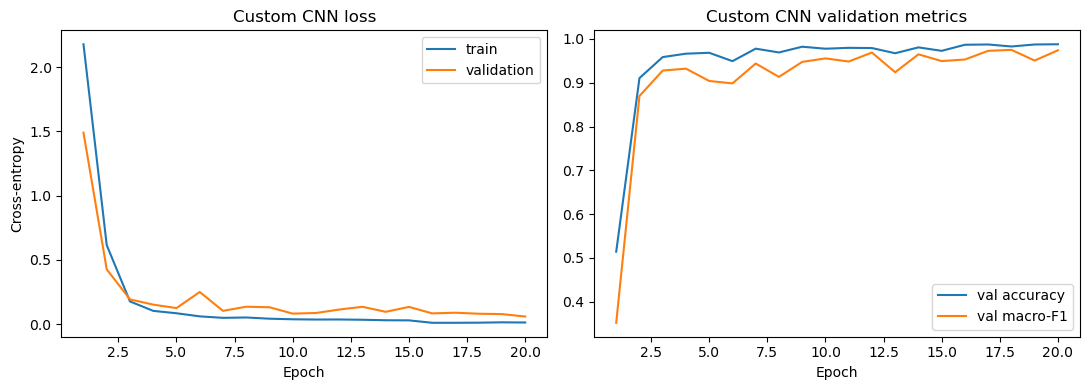

In [14]:
cnn_model, cnn_val_f1, cnn_hist, cnn_train_secs = fit_cnn(BEST_CNN, FINAL_EPOCHS)
cnn_epochs_run = len(cnn_hist)
torch.save(cnn_model.state_dict(), OUT / "custom_cnn_best.pt")
cnn_hist.to_csv(OUT / "cnn_training_history.csv", index=False)
print(f"Final CNN: best val macro-F1 {cnn_val_f1:.4f}, epochs run {cnn_epochs_run}, "
      f"training time {cnn_train_secs/60:.1f} min")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(cnn_hist.epoch, cnn_hist.train_loss, label="train"); ax[0].plot(cnn_hist.epoch, cnn_hist.val_loss, label="validation")
ax[0].set(title="Custom CNN loss", xlabel="Epoch", ylabel="Cross-entropy"); ax[0].legend()
ax[1].plot(cnn_hist.epoch, cnn_hist.val_acc, label="val accuracy"); ax[1].plot(cnn_hist.epoch, cnn_hist.val_macro_f1, label="val macro-F1")
ax[1].set(title="Custom CNN validation metrics", xlabel="Epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig(OUT / "cnn_learning_curves.png", dpi=300); plt.show()

### 12. Hyperparameter search — YOLOv8n-cls (Technique #2)
Fine-tuned from the official ImageNet-pretrained `yolov8n-cls.pt` weights. The optimizer is set explicitly (with `optimizer="auto"` Ultralytics would ignore `lr0`).
Horizontal flips are disabled (`fliplr=0`) because mirroring changes the meaning of some signs (e.g. *turn left* ↔ *turn right*), and random crops are limited to 80–100 % of the image (`scale=0.2`).

In [15]:
from ultralytics import YOLO
YOLO_DEVICE = 0 if DEVICE == "cuda" else "cpu"
YOLO_COMMON = dict(data=str(DATA_ROOT.resolve()), imgsz=YOLO_IMG, batch=YOLO_BATCH, seed=SEED,
                   deterministic=True, device=YOLO_DEVICE, workers=2, fliplr=0.0, scale=0.2,
                   project=str((OUT / "yolo_runs").resolve()), exist_ok=True, plots=False,
                   verbose=False, val=True)

def predict_yolo(model, paths, batch=128):
    preds = []
    for i in range(0, len(paths), batch):
        res = model.predict([str(p) for p in paths[i:i + batch]], imgsz=YOLO_IMG,
                            device=YOLO_DEVICE, verbose=False)
        preds += [int(model.names[r.probs.top1]) for r in res]
    return np.array(preds)

va_paths = sorted((DATA_ROOT / "val").rglob("*.png"))
va_true = np.array([int(p.parent.name) for p in va_paths])

yolo_rows = []
for opt_name, lr0 in itertools.product(YOLO_GRID["optimizer"], YOLO_GRID["lr0"]):
    name = f"tune_{opt_name}_lr{lr0:g}"
    print("YOLO config:", name)
    t0 = time.time()
    m = YOLO("yolov8n-cls.pt")
    m.train(epochs=TUNE_EPOCHS_YOLO, optimizer=opt_name, lr0=lr0, patience=TUNE_EPOCHS_YOLO,
            name=name, **YOLO_COMMON)
    best = YOLO(Path(m.trainer.save_dir) / "weights" / "best.pt")
    va_pred = predict_yolo(best, va_paths)
    f1 = f1_score(va_true, va_pred, average="macro", zero_division=0)
    yolo_rows.append({"optimizer": opt_name, "lr0": lr0, "best_val_macro_f1": round(f1, 4),
                      "val_acc": round(accuracy_score(va_true, va_pred), 4),
                      "minutes": round((time.time() - t0) / 60, 1)})
    print(f"  -> val macro-F1 {f1:.4f}")

yolo_search = pd.DataFrame(yolo_rows).sort_values("best_val_macro_f1", ascending=False)
yolo_search.to_csv(OUT / "yolo_grid_search.csv", index=False)
display(yolo_search)
BEST_YOLO = {"optimizer": yolo_search.iloc[0]["optimizer"], "lr0": float(yolo_search.iloc[0]["lr0"])}
print("Best YOLOv8n-cls configuration:", BEST_YOLO)

YOLO config: tune_SGD_lr0.01
Ultralytics 8.4.216  Python-3.13.9 torch-2.14.1+cpu CPU (AMD Ryzen 7 5825U with Radeon Graphics)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\Zaina\Downloads\results\gtsrb_cls, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=64, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=

,optimizer,lr0,best_val_macro_f1,val_acc,minutes
2,AdamW,0.010,0.9726,0.9830,5.9
3,AdamW,0.001,0.9382,0.9732,6.0
0,SGD,0.010,0.9144,0.9592,5.8
1,SGD,0.001,0.7377,0.8401,5.6


Best YOLOv8n-cls configuration: {'optimizer': 'AdamW', 'lr0': 0.01}


### 13. Final YOLOv8n-cls training with the best configuration

In [16]:
t0 = time.time()
yolo = YOLO("yolov8n-cls.pt")
yolo.train(epochs=FINAL_EPOCHS, patience=PATIENCE, name="final", **BEST_YOLO, **YOLO_COMMON)
yolo_train_secs = time.time() - t0
yolo_dir = Path(yolo.trainer.save_dir)
yolo_best_path = yolo_dir / "weights" / "best.pt"
yolo_best = YOLO(yolo_best_path)
yolo_hist = pd.read_csv(yolo_dir / "results.csv"); yolo_hist.columns = yolo_hist.columns.str.strip()
yolo_epochs_run = len(yolo_hist)
print(f"Final YOLOv8n-cls: epochs run {yolo_epochs_run}, training time {yolo_train_secs/60:.1f} min")
print("Weights:", yolo_best_path)

Ultralytics 8.4.216  Python-3.13.9 torch-2.14.1+cpu CPU (AMD Ryzen 7 5825U with Radeon Graphics)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\Zaina\Downloads\results\gtsrb_cls, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=64, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=final, nbs=64, nms=None, ops

### 14. Test-set evaluation, model size and inference time (Section 5.3 measures)

,Accuracy,Macro precision,Macro recall,Macro F1,Weighted F1,Parameters,Model size (MB),"Inference time (ms/image, CPU)",Training time (min),Epochs run
Model,,,,,,,,,,
Custom CNN,0.9883,0.9806,0.9874,0.9837,0.9883,331979,1.2848,2.1226,65.6471,20
YOLOv8n-cls,0.9858,0.9780,0.9781,0.9773,0.9858,1493371,2.9277,2.8433,21.7048,12


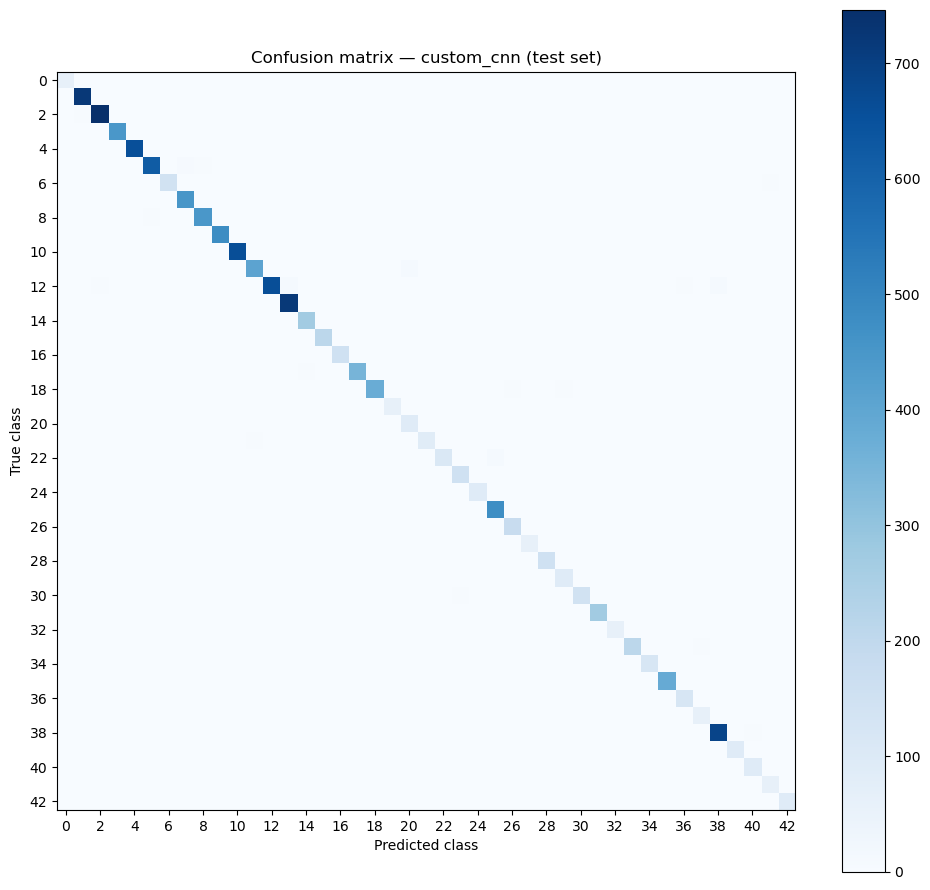

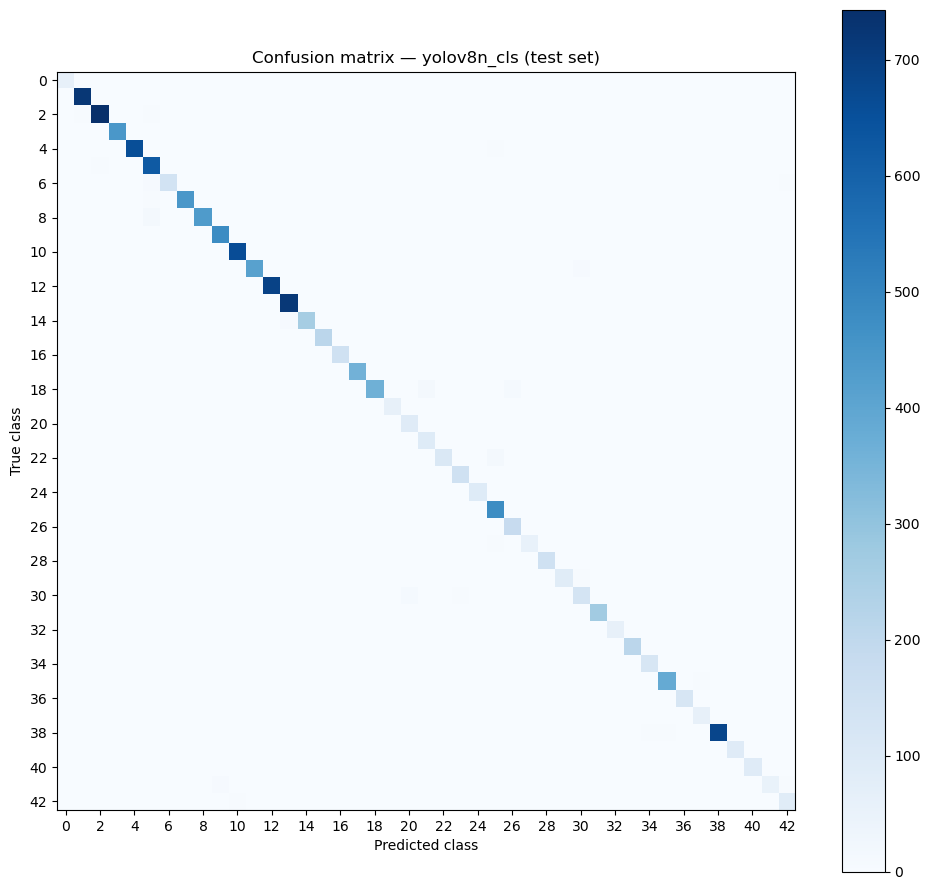

In [17]:
def metrics_row(name, y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    pw, rw, fw, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    return {"Model": name, "Accuracy": accuracy_score(y_true, y_pred),
            "Macro precision": p, "Macro recall": r, "Macro F1": f, "Weighted F1": fw}

# --- predictions on the untouched official test set ---
_, cnn_pred, _ = predict_cnn(cnn_model, make_loader(Xte, yte, 256, train=False))
te_true = yte.numpy()
yolo_pred = predict_yolo(yolo_best, test_paths)

# --- single-image CPU latency (batch size 1, model forward pass only, after warm-up) ---
def cnn_latency_ms(model, n=LATENCY_IMAGES, warmup=20):
    m = copy.deepcopy(model).cpu().eval()
    xs = [(Xte[i:i+1].float() / 255 - MEAN[:, None, None]) / STD[:, None, None] for i in range(n)]
    with torch.inference_mode():
        for x in xs[:warmup]: m(x)
        times = []
        for x in xs:
            t = time.perf_counter(); m(x); times.append((time.perf_counter() - t) * 1000)
    return float(np.mean(times))

def yolo_latency_ms(model, paths, n=LATENCY_IMAGES, warmup=20):
    for p in paths[:warmup]: model.predict(str(p), imgsz=YOLO_IMG, device="cpu", verbose=False)
    return float(np.mean([model.predict(str(p), imgsz=YOLO_IMG, device="cpu", verbose=False)[0].speed["inference"]
                          for p in paths[:n]]))

cnn_path = OUT / "custom_cnn_best.pt"
rows = [
    {**metrics_row("Custom CNN", te_true, cnn_pred),
     "Parameters": count_params(cnn_model), "Model size (MB)": cnn_path.stat().st_size / 1024**2,
     "Inference time (ms/image, CPU)": cnn_latency_ms(cnn_model),
     "Training time (min)": cnn_train_secs / 60, "Epochs run": cnn_epochs_run},
    {**metrics_row("YOLOv8n-cls", te_true, yolo_pred),
     "Parameters": sum(p.numel() for p in yolo_best.model.parameters()),
     "Model size (MB)": yolo_best_path.stat().st_size / 1024**2,
     "Inference time (ms/image, CPU)": yolo_latency_ms(yolo_best, test_paths),
     "Training time (min)": yolo_train_secs / 60, "Epochs run": yolo_epochs_run},
]
results = pd.DataFrame(rows).set_index("Model")
results.round(4).to_csv(OUT / "test_results_comparison.csv")
display(results.round(4))

# per-class reports and confusion matrices (for Section 6)
for name, pred in [("custom_cnn", cnn_pred), ("yolov8n_cls", yolo_pred)]:
    pd.DataFrame(classification_report(te_true, pred, output_dict=True, zero_division=0)).T \
      .to_csv(OUT / f"{name}_per_class_report.csv")
    cm = confusion_matrix(te_true, pred, labels=range(NUM_CLASSES))
    plt.figure(figsize=(10, 9)); plt.imshow(cm, cmap="Blues"); plt.colorbar()
    plt.title(f"Confusion matrix — {name} (test set)"); plt.xlabel("Predicted class"); plt.ylabel("True class")
    plt.xticks(range(0, 43, 2)); plt.yticks(range(0, 43, 2)); plt.tight_layout()
    plt.savefig(OUT / f"{name}_confusion_matrix.png", dpi=300); plt.show()

### 15. Values for the report tables (Section 5.4 optimum parameters)

In [18]:
opt_cnn = pd.DataFrame([
    ("Input size", f"{CNN_IMG} × {CNN_IMG} × 3"),
    ("Optimizer", "Adam (weight decay 1e-4)"),
    ("Learning rate", BEST_CNN["lr"]),
    ("Batch size", BEST_CNN["batch_size"]),
    ("Dropout rate", BEST_CNN["dropout"]),
    ("LR scheduler", "ReduceLROnPlateau (factor 0.5, patience 2)"),
    ("Loss function", "Cross-entropy"),
    ("Max epochs / early-stopping patience", f"{FINAL_EPOCHS} / {PATIENCE}"),
    ("Epochs actually run", cnn_epochs_run),
], columns=["Parameter", "Optimal value chosen"])

opt_yolo = pd.DataFrame([
    ("Initial weights", "yolov8n-cls.pt (ImageNet-pretrained)"),
    ("Input size", f"{YOLO_IMG} × {YOLO_IMG} × 3"),
    ("Optimizer", BEST_YOLO["optimizer"]),
    ("Initial learning rate (lr0)", BEST_YOLO["lr0"]),
    ("Batch size", YOLO_BATCH),
    ("Augmentation", "Ultralytics defaults, fliplr = 0, scale = 0.2"),
    ("Loss function", "Cross-entropy"),
    ("Max epochs / early-stopping patience", f"{FINAL_EPOCHS} / {PATIENCE}"),
    ("Epochs actually run", yolo_epochs_run),
], columns=["Parameter", "Optimal value chosen"])

opt_cnn.to_csv(OUT / "optimum_parameters_cnn.csv", index=False)
opt_yolo.to_csv(OUT / "optimum_parameters_yolo.csv", index=False)
print("Custom CNN"); display(opt_cnn)
print("YOLOv8n-cls"); display(opt_yolo)
print("All outputs saved in:", OUT.resolve())

Custom CNN


,Parameter,Optimal value chosen
0,Input size,48 × 48 × 3
1,Optimizer,Adam (weight decay 1e-4)
2,Learning rate,0.001
3,Batch size,64
4,Dropout rate,0.3
5,LR scheduler,"ReduceLROnPlateau (factor 0.5, patience 2)"
6,Loss function,Cross-entropy
7,Max epochs / early-stopping patience,20 / 5
8,Epochs actually run,20


YOLOv8n-cls


,Parameter,Optimal value chosen
0,Initial weights,yolov8n-cls.pt (ImageNet-pretrained)
1,Input size,64 × 64 × 3
2,Optimizer,AdamW
3,Initial learning rate (lr0),0.01
4,Batch size,64
5,Augmentation,"Ultralytics defaults, fliplr = 0, scale = 0.2"
6,Loss function,Cross-entropy
7,Max epochs / early-stopping patience,20 / 5
8,Epochs actually run,12


All outputs saved in: C:\Users\Zaina\Downloads\results
